In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow.keras import layers, models

IMG_SIZE = (150, 150)
BATCH_SIZE = 32

# Load dataset
(ds_train, ds_val), ds_info = tfds.load(
    'cats_vs_dogs',
    split=['train[:80%]', 'train[80%:]'],
    as_supervised=True,
    with_info=True
)

# Preprocessing
def preprocess(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    image = image / 255.0
    return image, label

ds_train = ds_train.map(preprocess).batch(BATCH_SIZE)
ds_val = ds_val.map(preprocess).batch(BATCH_SIZE)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.IXC1VV_4.0.1/cats_vs_dogs-train.tfrecord*...:   0%…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


In [2]:
model_scratch = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

model_scratch.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(model_scratch.summary())

history_scratch = model_scratch.fit(
    ds_train,
    validation_data=ds_val,
    epochs=10
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 39s 55ms/step - accuracy: 0.6370 - loss: 0.6376 - val_accuracy: 0.7190 - val_loss: 0.5624
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 47ms/step - accuracy: 0.7451 - loss: 0.5148 - val_accuracy: 0.7147 - val_loss: 0.5444
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.8067 - loss: 0.4223 - val_accuracy: 0.7741 - val_loss: 0.4706
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 27s 47ms/step - accuracy: 0.8441 - loss: 0.3562 - val_accuracy: 0.8040 - val_loss: 0.4397
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.8796 - loss: 0.2844 - val_accuracy: 0.8018 - val_loss: 0.4757
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.9104 - loss: 0.2164 - val_accuracy: 0.7902 - val_loss: 0.5407
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 28s 48ms/step - accuracy: 0.9297 - loss: 0.1744 - val_accuracy: 0.8022 - val_loss: 0.5991
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 27s 46ms/step - accuracy: 0.9512 - loss: 0.13

In [3]:
base_model = tf.keras.applications.VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(150,150,3)
)

base_model.trainable = False

transfer_model = models.Sequential([
    base_model,
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])

transfer_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print(transfer_model.summary())

history_transfer = transfer_model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=10
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

None
Epoch 1/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 95s 145ms/step - accuracy: 0.8706 - loss: 0.2983 - val_accuracy: 0.9011 - val_loss: 0.2294
Epoch 2/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 77s 131ms/step - accuracy: 0.9032 - loss: 0.2304 - val_accuracy: 0.9046 - val_loss: 0.2271
Epoch 3/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 78s 134ms/step - accuracy: 0.9118 - loss: 0.2076 - val_accuracy: 0.9157 - val_loss: 0.2051
Epoch 4/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 80s 137ms/step - accuracy: 0.9218 - loss: 0.1889 - val_accuracy: 0.9211 - val_loss: 0.2040
Epoch 5/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 80s 137ms/step - accuracy: 0.9264 - loss: 0.1721 - val_accuracy: 0.9177 - val_loss: 0.2056
Epoch 6/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 80s 137ms/step - accuracy: 0.9358 - loss: 0.1596 - val_accuracy: 0.9179 - val_loss: 0.2060
Epoch 7/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 80s 137ms/step - accuracy: 0.9380 - loss: 0.1506 - val_accuracy: 0.9222 - val_loss: 0.2015
Epoch 8/10
582/582 ━━━━━━━━━━━━━━━━━━━━ 83s 139ms/step - accuracy: 0.9420 - lo

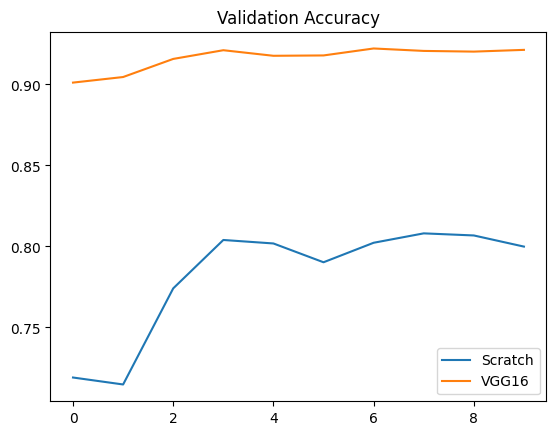

In [4]:
import matplotlib.pyplot as plt

plt.plot(history_scratch.history['val_accuracy'], label='Scratch')
plt.plot(history_transfer.history['val_accuracy'], label='VGG16')
plt.legend()
plt.title("Validation Accuracy")
plt.show()

The scratch model overfits because its high capacity allows it to "memorize" specific pixel patterns and noise in a small dataset rather than learning general concepts. In contrast, transfer learning succeeds by using a pre-trained "visual vocabulary" from millions of images. By freezing the base layers, you force the model to use proven, generalized features, which prevents it from obsessing over the tiny details of your specific training set and leads to much better performance on new data.